# FIREGUARD ID — 07: Spatial Prioritization & 6-Module MILP Optimization

            - Modules: `src/prioritization/prioritizer.py` and `src/optimization/` (Modules 1–6 via `scipy.optimize.milp` HiGHS).
            - **Synthetic Scenario Caveat (`is_synthetic_scenario=True`):** Real BPBD/Manggala Agni facility, fleet, personnel, and OSM road network inventories are absent locally (`SRC-08`). All optimization results represent synthetic planning scenarios anchored to Riau's verified 853-cell Phase 7 spatial priority grid, using `haversine_km * 1.35` at `45 km/h` as a travel proxy.


In [1]:
import os
import sys
from pathlib import Path

REPO_ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
if str(REPO_ROOT) not in sys.path:
    sys.path.insert(0, str(REPO_ROOT))
os.environ.setdefault("MPLCONFIGDIR", str(REPO_ROOT / ".mplconfig"))

import json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from src.utils import load_yaml, resolve_path

proj_cfg = load_yaml("config/project.yaml", repo_root=REPO_ROOT)
print(f"Project: {proj_cfg['project']['name']} v{proj_cfg['project']['version']} | Pilot: {proj_cfg['project']['pilot_region']}")

from src.prioritization.prioritizer import run_phase7_prioritization
from src.optimization.common import load_optimization_inputs
from src.optimization import (
    base_location,
    base_capacity,
    fleet_equipment,
    personnel,
    comms_coordination,
    budget_operational,
)


Project: FIREGUARD-ID v2.0.0 | Pilot: Riau Province, Indonesia


## 1. Phase 7 Spatial Prioritization & Weight Sensitivity


In [2]:
processed_dir = resolve_path(proj_cfg["paths"]["processed_dir"], repo_root=REPO_ROOT)
reports_dir = resolve_path(proj_cfg["paths"]["reports_dir"], repo_root=REPO_ROOT)
outputs_dir = resolve_path(proj_cfg["paths"]["outputs_dir"], repo_root=REPO_ROOT)

df_prio = pd.read_parquet(processed_dir / "riau_spatial_priorities.parquet")
prio_sum = json.loads((reports_dir / "prioritization" / "prioritization_summary.json").read_text(encoding="utf-8"))
sens_df = pd.read_csv(reports_dir / "prioritization" / "sensitivity_analysis.csv")

print("Priority Classes:", prio_sum["priority_class_counts"])
print("Spearman(Vulnerability, Priority):", prio_sum["vulnerability_vs_priority_spearman"])
display(sens_df)
display(df_prio.nsmallest(10, "priority_rank")[
    ["priority_rank", "grid_id", "center_lat", "center_lon", "hotspot_count", "fire_days", "vulnerability_class", "priority_score", "priority_class"]
])


Priority Classes: {'Tier 4 (Baseline Monitoring - Bottom 50%)': 427, 'Tier 3 (Elevated Priority - Top 25-50%)': 213, 'Tier 2 (High Priority - Top 10-25%)': 128, 'Tier 1 (Critical Priority - Top 10%)': 85}
Spearman(Vulnerability, Priority): 0.973754


,scenario,vuln,persistence,corridor,remoteness,spearman_rho_vs_base,top85_jaccard_vs_base,max_rank_shift_cells
0,balanced_operational,0.45,0.25,0.20,0.10,1.000000,1.0000,0
1,vulnerability_dominant,0.70,0.15,0.10,0.05,0.996523,0.7526,85
2,corridor_containment,0.35,0.20,0.35,0.10,0.993496,0.8085,99
3,remote_access_focus,0.40,0.20,0.15,0.25,0.987407,0.7172,119


,priority_rank,grid_id,center_lat,center_lon,hotspot_count,fire_days,vulnerability_class,priority_score,priority_class
33,1,GRID_0033,0.65,100.35,182,67,High / Chronic-Intense,0.910082,Tier 1 (Critical Priority - Top 10%)
575,2,GRID_0575,-0.85,102.35,73,41,High / Chronic-Intense,0.906071,Tier 1 (Critical Priority - Top 10%)
34,3,GRID_0034,0.75,100.35,130,54,High / Chronic-Intense,0.905952,Tier 1 (Critical Priority - Top 10%)
91,4,GRID_0091,2.05,100.55,353,37,High / Chronic-Intense,0.901538,Tier 1 (Critical Priority - Top 10%)
548,5,GRID_0548,-0.85,102.25,67,29,High / Chronic-Intense,0.892954,Tier 1 (Critical Priority - Top 10%)
49,6,GRID_0049,2.35,100.35,182,35,High / Chronic-Intense,0.890536,Tier 1 (Critical Priority - Top 10%)
767,7,GRID_0767,-0.15,103.15,68,22,High / Chronic-Intense,0.888438,Tier 1 (Critical Priority - Top 10%)
342,8,GRID_0342,1.65,101.45,763,472,High / Chronic-Intense,0.887985,Tier 1 (Critical Priority - Top 10%)
47,9,GRID_0047,2.15,100.35,46,15,High / Chronic-Intense,0.886127,Tier 1 (Critical Priority - Top 10%)
48,10,GRID_0048,2.25,100.35,100,24,High / Chronic-Intense,0.879780,Tier 1 (Critical Priority - Top 10%)


## 2. Synthetic-Scenario Optimization Summary Across All 6 Modules


In [3]:
opt_dir = outputs_dir / "optimization"
m1 = json.loads((opt_dir / "m1_m2" / "m1_summary.json").read_text(encoding="utf-8"))
m2 = json.loads((opt_dir / "m1_m2" / "m2_summary.json").read_text(encoding="utf-8"))
m3 = json.loads((opt_dir / "m3_m4" / "module3_summary.json").read_text(encoding="utf-8"))
m4 = json.loads((opt_dir / "m3_m4" / "module4_summary.json").read_text(encoding="utf-8"))
m5 = json.loads((opt_dir / "m5_m6" / "m5_summary.json").read_text(encoding="utf-8"))
m6 = json.loads((opt_dir / "m5_m6" / "m6_summary.json").read_text(encoding="utf-8"))

for label, d in [("M1 Base Location", m1), ("M2 Base Capacity", m2), ("M3 Fleet", m3), ("M4 Personnel", m4), ("M5 Comms", m5), ("M6 Budget", m6)]:
    assert d["is_synthetic_scenario"] is True
    print(f"{label}: is_synthetic_scenario={d['is_synthetic_scenario']}")

print("M1 (p=10) Priority Covered:", m1["default_solution"]["covered_priority_pct"], "% | Tier-1 Covered:", m1["default_solution"]["tier1_cells_covered_radius"])
print("M2 Default CAPEX (M IDR):", m2["default_solution"]["total_capex_million_idr"], "| Tiers:", m2["default_solution"]["tier_counts"])
print("M3 Fleet Demand Coverage:", m3["nominal_summary"]["demand_coverage_pct"], "%")
print("M4 Personnel Staffed Coverage:", m4["nominal_summary"]["staffed_demand_coverage_pct"], "% | Safety Violations:", m4["nominal_summary"]["safety_violations"])
print("M5 Relays Bases Covered:", m5["default_solution"]["metrics"]["bases_covered"], "/", m5["default_solution"]["metrics"]["total_bases"])


M1 Base Location: is_synthetic_scenario=True
M2 Base Capacity: is_synthetic_scenario=True
M3 Fleet: is_synthetic_scenario=True
M4 Personnel: is_synthetic_scenario=True
M5 Comms: is_synthetic_scenario=True
M6 Budget: is_synthetic_scenario=True
M1 (p=10) Priority Covered: 33.59 % | Tier-1 Covered: 38
M2 Default CAPEX (M IDR): 31800.0 | Tiers: {'small': 1, 'medium': 6, 'large': 3}
M3 Fleet Demand Coverage: 100.0 %
M4 Personnel Staffed Coverage: 100.0 % | Safety Violations: 0
M5 Relays Bases Covered: 10 / 10


## 3. Module 6 CAPEX + OPEX Cost-Coverage Pareto Trade-Off


,budget_million_idr,total_cost_million_idr,active_bases,personnel,relays,regional_demand_served_pct,rapid_35km_coverage_pct
0,15000.0,14973.0,4,24,3,43.98,14.08
1,25000.0,24988.0,7,54,4,63.42,23.95
2,35000.0,34848.0,8,84,5,78.87,27.26
3,50000.0,49406.0,10,148,6,92.66,33.59
4,65000.0,61862.0,10,196,6,100.00,33.59


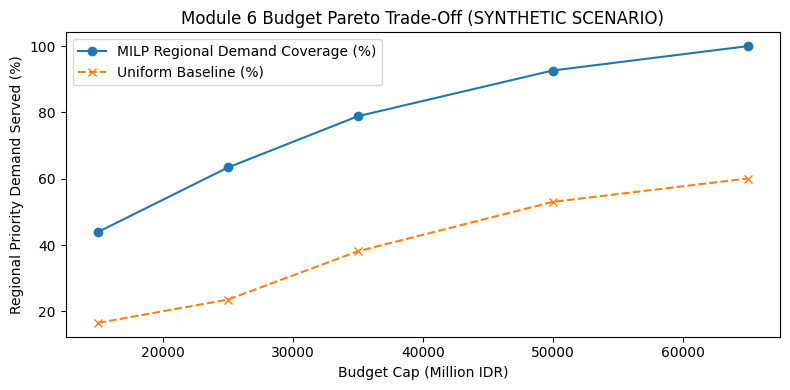

In [4]:
pareto = pd.read_parquet(opt_dir / "m5_m6" / "m6_pareto_tradeoff.parquet")
display(pareto[["budget_million_idr", "total_cost_million_idr", "active_bases", "personnel", "relays", "regional_demand_served_pct", "rapid_35km_coverage_pct"]])

fig, ax = plt.subplots(figsize=(8, 4))
ax.plot(pareto["budget_million_idr"], pareto["regional_demand_served_pct"], marker="o", label="MILP Regional Demand Coverage (%)")
ax.plot(pareto["budget_million_idr"], pareto["baseline_regional_demand_served_pct"], marker="x", linestyle="--", label="Uniform Baseline (%)")
ax.set_title("Module 6 Budget Pareto Trade-Off (SYNTHETIC SCENARIO)")
ax.set_xlabel("Budget Cap (Million IDR)")
ax.set_ylabel("Regional Priority Demand Served (%)")
ax.legend()
plt.tight_layout()
plt.show()
